<a href="https://colab.research.google.com/github/yurani-duque/Taller2_ETL_Spotify_Grammys/blob/main/ml_clasificacion_cancer_mama.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Actividad: construcción de un modelo de clasificación

**Fuente de datos:** conjunto *Breast Cancer Wisconsin (Diagnostic)* de `scikit-learn`.

## Propósito

Construir un flujo básico de aprendizaje automático que permita preparar datos, entrenar y seleccionar un clasificador, evaluar su desempeño, serializarlo y utilizarlo para realizar una inferencia sobre nuevos registros.

> **Importante:** este notebook es una plantilla de trabajo. Se entrega la fuente de datos y la secuencia de actividades.

El conjunto de datos es de uso educativo. La variable objetivo distingue dos clases (`malignant` y `benign`). No debe interpretarse el ejercicio como una herramienta de diagnóstico médico.


## 1. Cargar la fuente de datos

La fuente está incluida en `scikit-learn`; no es necesario descargar un archivo externo.

Documentación: https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_breast_cancer.html

El siguiente bloque únicamente carga los datos y los organiza en un DataFrame. A partir de aquí, el desarrollo queda a cargo del estudiante.


In [1]:
from sklearn.datasets import load_breast_cancer
import pandas as pd
import numpy as np

# Carga de la fuente de datos
dataset = load_breast_cancer(as_frame=True)

X = dataset.data
y = dataset.target

df = X.copy()
df["target"] = y

print("Dimensiones:", df.shape)
display(df.head())


Dimensiones: (569, 31)


,mean radius,mean texture,mean perimeter,mean area,mean smoothness,mean compactness,mean concavity,mean concave points,mean symmetry,mean fractal dimension,...,worst texture,worst perimeter,worst area,worst smoothness,worst compactness,worst concavity,worst concave points,worst symmetry,worst fractal dimension,target
0,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,0.07871,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,0
1,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,0.05667,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,0
2,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,0.05999,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,0
3,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,0.09744,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,0
4,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,0.05883,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,0


## 2. Actividades a desarrollar

Complete las actividades en orden. En cada etapa, documente brevemente las decisiones tomadas y los resultados obtenidos.

1. **Comprensión de los datos**
   - Identificar el número de registros y variables.
   - Identificar cuáles son las variables predictoras y cuál es la variable objetivo.
   - Revisar tipos de datos, valores faltantes, duplicados y estadísticas descriptivas.
   - Analizar la distribución de las clases y determinar si existe desbalance.

2. **Preparación de los datos**
   - Definir si se requieren transformaciones o tratamiento de valores faltantes.
   - Determinar si las variables necesitan escalamiento u otro preprocesamiento.
   - Evitar fuga de información (*data leakage*): los parámetros de cualquier transformación deben aprenderse únicamente con los datos de entrenamiento.

3. **Separación de conjuntos**
   - Dividir los datos en conjuntos de entrenamiento, validación y prueba.
   - Utilizar una estrategia de división apropiada para clasificación y conservar la proporción de clases cuando corresponda.
   - Reportar el tamaño y la distribución de clases de cada conjunto.
   - Justificar las proporciones seleccionadas.

4. **Selección y entrenamiento del modelo**
   - Seleccionar al menos un algoritmo de clasificación que no sea regresión lineal ni logística usada como modelo de regresión.
   - Entrenar el modelo con el conjunto de entrenamiento.
   - Justificar por qué eligió ese algoritmo.
   - Si lo considera pertinente, comparar al menos dos configuraciones o algoritmos.

5. **Validación y selección**
   - Evaluar las alternativas con el conjunto de validación.
   - Comparar resultados y seleccionar una configuración final.
   - Explicar qué métrica utilizó como criterio principal y por qué.
   - No utilizar el conjunto de prueba para tomar decisiones sobre el modelo.

6. **Evaluación**
   - Evaluar el modelo seleccionado en entrenamiento y validación.
   - Una vez tomada la decisión final, evaluar el desempeño en el conjunto de prueba.
   - Calcular y analizar, como mínimo:
     - Accuracy.
     - Precision.
     - Recall.
     - F1-score.
     - ROC-AUC.
   - Incluir matriz de confusión y reporte de clasificación.
   - Explicar qué significan los falsos positivos y falsos negativos en el contexto del conjunto de datos.
   - Comparar las métricas entre conjuntos e identificar posibles señales de sobreajuste o subajuste.

7. **Serialización**
   - Serializar el modelo final junto con los elementos de preprocesamiento necesarios.
   - Guardar el artefacto en un archivo.
   - Incluir metadatos mínimos: nombre del algoritmo, versión o identificador del modelo, variables esperadas y fecha de creación.
   - Explicar por qué es importante conservar el preprocesamiento junto con el modelo.

8. **Carga e inferencia**
   - Cargar el artefacto serializado en una sección independiente del flujo.
   - Construir al menos un registro nuevo con las variables requeridas.
   - Validar que el registro tenga las columnas y tipos esperados.
   - Ejecutar la inferencia.
   - Mostrar la clase predicha y, si el modelo lo permite, la probabilidad o puntuación asociada a cada clase.

9. **Conclusiones**
   - Resumir el desempeño del modelo.
   - Explicar las limitaciones del ejercicio.
   - Indicar qué controles adicionales serían necesarios antes de utilizar un modelo similar en un entorno productivo.


## 3. Desarrollo

### Etapa 1 — Comprensión de los datos

Realice la exploración solicitada. Incluya tablas o visualizaciones cuando aporten información útil.


In [2]:
import warnings
warnings.filterwarnings("ignore")

import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
SEED = 42  # una sola semilla para que todo el flujo sea reproducible

# 1.1 Tamaño y estructura
print(f"Registros: {df.shape[0]}  |  Variables predictoras: {X.shape[1]}  |  Variable objetivo: 'target'")
print("Codificación de 'target':", {i: str(n) for i, n in enumerate(dataset.target_names)})

# 1.2 Tipos de dato, faltantes y duplicados
print("\nTipos de dato de las predictoras:")
print(X.dtypes.value_counts().to_string())
print("\nValores faltantes (total):", int(df.isna().sum().sum()))
print("Filas duplicadas:", int(df.duplicated().sum()))

# 1.3 Estadísticas descriptivas
display(X.describe().T.round(3))

Registros: 569  |  Variables predictoras: 30  |  Variable objetivo: 'target'
Codificación de 'target': {0: 'malignant', 1: 'benign'}

Tipos de dato de las predictoras:
float64    30

Valores faltantes (total): 0
Filas duplicadas: 0


,count,mean,std,min,25%,50%,75%,max
mean radius,569.0,14.127,3.524,6.981,11.700,13.370,15.780,28.110
mean texture,569.0,19.290,4.301,9.710,16.170,18.840,21.800,39.280
mean perimeter,569.0,91.969,24.299,43.790,75.170,86.240,104.100,188.500
mean area,569.0,654.889,351.914,143.500,420.300,551.100,782.700,2501.000
mean smoothness,569.0,0.096,0.014,0.053,0.086,0.096,0.105,0.163
mean compactness,569.0,0.104,0.053,0.019,0.065,0.093,0.130,0.345
mean concavity,569.0,0.089,0.080,0.000,0.030,0.062,0.131,0.427
mean concave points,569.0,0.049,0.039,0.000,0.020,0.034,0.074,0.201
mean symmetry,569.0,0.181,0.027,0.106,0.162,0.179,0.196,0.304
mean fractal dimension,569.0,0.063,0.007,0.050,0.058,0.062,0.066,0.097


**Hallazgos**

| Aspecto | Resultado |
|---|---|
| Registros | 569 |
| Variables predictoras | 30, todas numéricas (`float64`) |
| Variable objetivo | `target` (0 = *malignant*, 1 = *benign*) |
| Valores faltantes | 0 |
| Filas duplicadas | 0 |

Las 30 predictoras son 10 medidas de los núcleos celulares (radio, textura, área, etc.) calculadas como promedio (`mean`), error estándar (`error`) y peor valor (`worst`). Las escalas son muy distintas: `mean area` ≈ 655 frente a `mean smoothness` ≈ 0.096.


,clase (target),registros,proporción
0,malignant (0),212,0.373
1,benign (1),357,0.627


Razón clase mayoritaria / minoritaria: 1.68 : 1


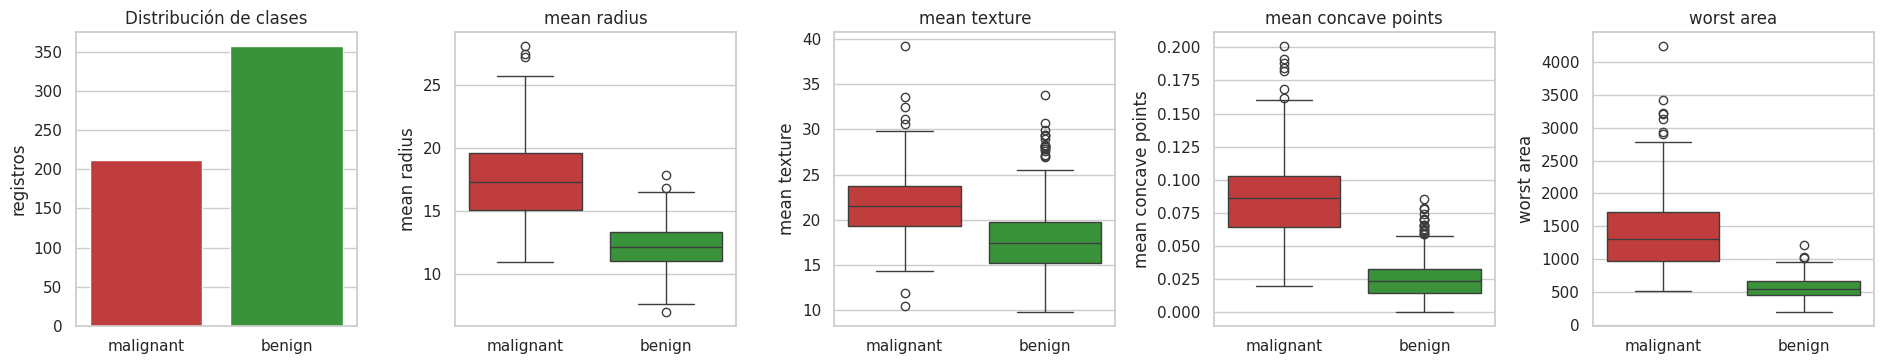

In [3]:
# 1.4 Distribución de clases
conteo = y.value_counts().sort_index()
distribucion = pd.DataFrame({
    "clase (target)": [f"{dataset.target_names[i]} ({i})" for i in conteo.index],
    "registros": conteo.values,
    "proporción": (conteo / len(y)).round(3).values,
})
display(distribucion)
print(f"Razón clase mayoritaria / minoritaria: {conteo.max() / conteo.min():.2f} : 1")

colores = {"malignant": "#d62728", "benign": "#2ca02c"}
nombres = df["target"].map(dict(enumerate(dataset.target_names)))

fig, axes = plt.subplots(1, 5, figsize=(19, 3.8))
sns.barplot(x=[dataset.target_names[i] for i in conteo.index], y=conteo.values,
            hue=[dataset.target_names[i] for i in conteo.index], palette=colores, legend=False, ax=axes[0])
axes[0].set_title("Distribución de clases")
axes[0].set_ylabel("registros")
for ax, col in zip(axes[1:], ["mean radius", "mean texture", "mean concave points", "worst area"]):
    sns.boxplot(x=nombres, y=df[col], hue=nombres, palette=colores, legend=False,
                order=["malignant", "benign"], ax=ax)
    ax.set_title(col)
    ax.set_xlabel("")
plt.tight_layout()
plt.show()

**Balance de clases**

- 212 casos *malignant* (37.3 %) y 357 *benign* (62.7 %): hay un desbalance **moderado** (1.68 a 1).
- Aun así, *accuracy* sería engañosa: un modelo que siempre dijera «benigno» acertaría el 62.7 % sin detectar ningún maligno.
- Los diagramas de caja muestran que `mean radius`, `mean concave points` y `worst area` separan bien las clases.


In [4]:
# 1.5 Redundancia entre variables (multicolinealidad)
corr = X.corr().abs()
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().sort_values(ascending=False))
print(f"Pares de variables con |r| > 0.90: {int((pares > 0.90).sum())} de {len(pares)} pares posibles")
display(pares.head(6).round(3).rename("|correlación|").to_frame())

Pares de variables con |r| > 0.90: 21 de 435 pares posibles


,,|correlación|
mean radius,mean perimeter,0.998
worst radius,worst perimeter,0.994
mean radius,mean area,0.987
mean perimeter,mean area,0.987
worst radius,worst area,0.984
worst perimeter,worst area,0.978


Hay 21 pares de variables con correlación mayor a 0.90 (por ejemplo, radio–perímetro 0.998). Es normal, porque miden casi lo mismo.


### Etapa 2 — Preparación de los datos

Implemente y justifique el tratamiento de datos que considere necesario.


In [5]:
# 2.1 Valores faltantes: no hay, por lo tanto no se requiere imputación
assert df.isna().sum().sum() == 0, "Se encontraron faltantes: habría que imputar dentro del pipeline"

# 2.2 ¿Se necesita escalamiento? Se compara la magnitud de las variables
rangos = X.agg(["min", "max"]).T
rangos["rango"] = rangos["max"] - rangos["min"]
extremos = rangos.sort_values("rango").iloc[[0, 1, -2, -1]]
display(extremos.round(4))
print(f"Cociente entre el mayor y el menor rango: {rangos['rango'].max() / rangos['rango'].min():,.0f} veces")

# 2.3 Valores atípicos (regla 1.5×IQR): solo diagnóstico, no se eliminan
q1, q3 = X.quantile(0.25), X.quantile(0.75)
iqr = q3 - q1
fuera = (X < q1 - 1.5 * iqr) | (X > q3 + 1.5 * iqr)
print(f"\nCeldas fuera de 1.5×IQR: {fuera.values.mean():.2%} del total")
print(f"Registros con al menos un atípico: {fuera.any(axis=1).mean():.1%}")

,min,max,rango
fractal dimension error,0.0009,0.0298,0.0289
smoothness error,0.0017,0.0311,0.0294
mean area,143.5000,2501.0000,2357.5000
worst area,185.2000,4254.0000,4068.8000


Cociente entre el mayor y el menor rango: 140,569 veces

Celdas fuera de 1.5×IQR: 3.56% del total
Registros con al menos un atípico: 30.1%


**Decisiones de preparación**

| Pregunta | Decisión | Justificación |
|---|---|---|
| ¿Valores faltantes? | No se imputa | No hay faltantes. |
| ¿Variables categóricas? | No se codifica | Todas son numéricas y `target` ya es 0/1. |
| ¿Escalamiento? | **Sí, `StandardScaler`** | El rango de la variable más amplia es ≈ 140 000 veces el de la más estrecha; SVM y KNN usan distancias y quedarían dominados por `area`. |
| ¿Valores atípicos? | No se eliminan | Son medidas reales y en la clase maligna los valores altos son informativos; eliminarlos quitaría casos relevantes. |

Los modelos de árboles no necesitan escalamiento, por eso sus pipelines no lo incluyen.


In [6]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

def construir_pipeline(estimador, escalar=True):
    """Encadena el preprocesamiento y el clasificador en un solo objeto.

    Al ajustar el Pipeline con X_train, el StandardScaler aprende media y
    desviación únicamente de entrenamiento y luego solo las aplica a
    validación/prueba (sin fuga de información).
    """
    pasos = [("scaler", StandardScaler())] if escalar else []
    pasos.append(("clf", estimador))
    return Pipeline(pasos)

print("Función de preprocesamiento lista: StandardScaler dentro de un Pipeline.")

Función de preprocesamiento lista: StandardScaler dentro de un Pipeline.


**Evitar fuga de información (*data leakage*):** el escalador va dentro de un `Pipeline`. Al ajustarlo con `X_train`, la media y la desviación se aprenden solo con entrenamiento; a validación y prueba únicamente se les aplican.


### Etapa 3 — Separación de entrenamiento, validación y prueba

Realice la separación. Muestre los tamaños y la distribución de clases de cada conjunto.


In [7]:
from sklearn.model_selection import train_test_split

# Paso 1: se aparta el 20 % para PRUEBA (no se toca hasta la evaluación final)
X_tmp, X_test, y_tmp, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=SEED)

# Paso 2: del 80 % restante, el 25 % (= 20 % del total) pasa a VALIDACIÓN
X_train, X_val, y_train, y_val = train_test_split(
    X_tmp, y_tmp, test_size=0.25, stratify=y_tmp, random_state=SEED)

filas = []
for nombre, ys in {"entrenamiento": y_train, "validación": y_val, "prueba": y_test}.items():
    filas.append({
        "conjunto": nombre,
        "registros": len(ys),
        "% del total": round(100 * len(ys) / len(y), 1),
        "malignant (0)": int((ys == 0).sum()),
        "benign (1)": int((ys == 1).sum()),
        "% malignant": round(100 * (ys == 0).mean(), 1),
    })
display(pd.DataFrame(filas).set_index("conjunto"))
print(f"Proporción de malignant en el conjunto completo: {100 * (y == 0).mean():.1f} %")

# Comprobación: ningún registro aparece en dos conjuntos
assert not (set(X_train.index) & set(X_val.index))
assert not (set(X_train.index) & set(X_test.index))
assert not (set(X_val.index) & set(X_test.index))
assert len(X_train) + len(X_val) + len(X_test) == len(X)
print("Verificación OK: los tres conjuntos son disjuntos y suman el total.")

,registros,% del total,malignant (0),benign (1),% malignant
conjunto,,,,,
entrenamiento,341,59.9,127,214,37.2
validación,114,20.0,43,71,37.7
prueba,114,20.0,42,72,36.8


Proporción de malignant en el conjunto completo: 37.3 %
Verificación OK: los tres conjuntos son disjuntos y suman el total.


**División 60 % entrenamiento / 20 % validación / 20 % prueba, estratificada**

| Conjunto | Registros | % *malignant* |
|---|---|---|
| Entrenamiento | 341 | 37.2 % |
| Validación | 114 | 37.7 % |
| Prueba | 114 | 36.8 % |

- **Estratificada** (`stratify`): mantiene la proporción de clases (≈ 37 % malignant) en los tres conjuntos.
- **Dos divisiones sucesivas:** primero se aparta el 20 % de prueba y del resto se toma el 25 % (= 20 % del total) para validación.
- **Proporciones:** con solo 569 registros, 20 % deja 43 y 42 casos malignos en validación y prueba, suficientes para estimar el *recall* sin quitarle demasiado al entrenamiento.
- `random_state=42` hace la división reproducible.


### Etapa 4 — Entrenamiento de modelos

Entrene al menos un clasificador. Si compara alternativas, mantenga el conjunto de prueba reservado.


In [8]:
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, classification_report,
                             roc_curve)

MALIGNO = 0  # clase de interés: es la positiva para precision, recall y F1

def evaluar(modelo, X_, y_):
    """Métricas con 'malignant' como clase positiva."""
    pred = modelo.predict(X_)
    col_maligno = list(modelo.classes_).index(MALIGNO)
    prob_maligno = modelo.predict_proba(X_)[:, col_maligno]
    return {
        "accuracy":  accuracy_score(y_, pred),
        "precision": precision_score(y_, pred, pos_label=MALIGNO),
        "recall":    recall_score(y_, pred, pos_label=MALIGNO),
        "f1":        f1_score(y_, pred, pos_label=MALIGNO),
        "roc_auc":   roc_auc_score((y_ == MALIGNO).astype(int), prob_maligno),
    }

# Candidatos: 4 familias de algoritmos y 2 configuraciones de cada una (salvo GB y árbol)
modelos = {
    "SVM RBF (C=1)":        construir_pipeline(SVC(kernel="rbf", C=1,  gamma="scale", probability=True, random_state=SEED)),
    "SVM RBF (C=10)":       construir_pipeline(SVC(kernel="rbf", C=10, gamma="scale", probability=True, random_state=SEED)),
    "KNN (k=5)":            construir_pipeline(KNeighborsClassifier(n_neighbors=5)),
    "KNN (k=11)":           construir_pipeline(KNeighborsClassifier(n_neighbors=11)),
    "Random Forest (prof. libre)": construir_pipeline(RandomForestClassifier(n_estimators=300, random_state=SEED), escalar=False),
    "Random Forest (prof.=4)":     construir_pipeline(RandomForestClassifier(n_estimators=300, max_depth=4, random_state=SEED), escalar=False),
    "Gradient Boosting":    construir_pipeline(GradientBoostingClassifier(random_state=SEED), escalar=False),
    "Árbol de decisión (prof.=4)": construir_pipeline(DecisionTreeClassifier(max_depth=4, random_state=SEED), escalar=False),
}

# Todos se entrenan SOLO con el conjunto de entrenamiento
for nombre, modelo in modelos.items():
    modelo.fit(X_train, y_train)
print(f"{len(modelos)} modelos entrenados con {len(X_train)} registros de entrenamiento.")
print("Orden de clases en los clasificadores:", [int(c) for c in modelos['KNN (k=5)'].classes_], "(0 = malignant, 1 = benign)")

8 modelos entrenados con 341 registros de entrenamiento.
Orden de clases en los clasificadores: [0, 1] (0 = malignant, 1 = benign)


**Algoritmos elegidos y por qué** (ninguno es regresión lineal ni logística)

| Algoritmo | Configuraciones | Motivo |
|---|---|---|
| **SVM (kernel RBF)** | `C = 1` y `C = 10` | Funciona bien con datos numéricos escalados y fronteras no lineales; `C` controla la regularización. |
| **KNN** | `k = 5` y `k = 11` | Línea base simple basada en distancias. |
| **Random Forest** | profundidad libre y `max_depth = 4` | Conjunto de árboles, robusto a escalas y atípicos. |
| **Gradient Boosting** | por defecto | Conjunto de árboles muy competitivo en datos tabulares. |
| **Árbol de decisión** | `max_depth = 4` | Línea base interpretable. |

Todos se entrenan solo con el conjunto de entrenamiento; la prueba sigue reservada.


### Etapa 5 — Validación y selección del modelo

Compare las alternativas o configuraciones con el conjunto de validación y justifique la selección.


In [9]:
filas = []
for nombre, modelo in modelos.items():
    m_tr = evaluar(modelo, X_train, y_train)
    m_va = evaluar(modelo, X_val, y_val)
    filas.append({
        "modelo": nombre,
        "val_recall": m_va["recall"], "val_f1": m_va["f1"],
        "val_precision": m_va["precision"], "val_accuracy": m_va["accuracy"],
        "val_roc_auc": m_va["roc_auc"],
        "brecha_f1 (train-val)": abs(m_tr["f1"] - m_va["f1"]),
    })

tabla_val = pd.DataFrame(filas).set_index("modelo").round(4)
display(tabla_val.sort_values(["val_recall", "val_f1"], ascending=False))

,val_recall,val_f1,val_precision,val_accuracy,val_roc_auc,brecha_f1 (train-val)
modelo,,,,,,
SVM RBF (C=1),0.9535,0.9762,1.0000,0.9825,0.9974,0.0000
SVM RBF (C=10),0.9535,0.9762,1.0000,0.9825,0.9977,0.0238
Gradient Boosting,0.9535,0.9425,0.9318,0.9561,0.9923,0.0575
Random Forest (prof. libre),0.9302,0.9412,0.9524,0.9561,0.9797,0.0588
Random Forest (prof.=4),0.9302,0.9412,0.9524,0.9561,0.9800,0.0509
Árbol de decisión (prof.=4),0.9070,0.9176,0.9286,0.9386,0.9586,0.0627
KNN (k=5),0.8837,0.9383,1.0000,0.9561,0.9835,0.0259
KNN (k=11),0.8372,0.9114,1.0000,0.9386,0.9934,0.0486


**Criterio principal: *recall* de la clase maligna.** Un falso negativo (maligno clasificado como benigno) es el error más grave, porque no se detectaría un caso que requiere atención; un falso positivo solo genera estudios adicionales. Como desempate se usa el F1 y, después, la menor brecha entre entrenamiento y validación. No se usa *accuracy* como criterio porque favorece a la clase mayoritaria.

**Lectura de la tabla**

- **Tres modelos empatan en el mejor *recall*** (0.9535, es decir 41 de 43 malignos): SVM `C=1`, SVM `C=10` y Gradient Boosting.
- Los dos SVM superan a Gradient Boosting en F1 (0.9762 frente a 0.9535).
- KNN queda por debajo (recall 0.88 y 0.84); Random Forest y el árbol, en un nivel intermedio (0.93 y 0.91).


In [10]:
# Regla de selección (definida antes de mirar la prueba):
#   1) mayor recall de 'malignant' en validación
#   2) si empatan, mayor F1
#   3) si siguen empatados, menor brecha entre entrenamiento y validación (menos sobreajuste)
ranking = tabla_val.sort_values(["val_recall", "val_f1", "brecha_f1 (train-val)"],
                                ascending=[False, False, True])
nombre_final = ranking.index[0]
modelo_final = modelos[nombre_final]

print(">>> Modelo seleccionado:", nombre_final)
display(ranking.head(3))

>>> Modelo seleccionado: SVM RBF (C=1)


,val_recall,val_f1,val_precision,val_accuracy,val_roc_auc,brecha_f1 (train-val)
modelo,,,,,,
SVM RBF (C=1),0.9535,0.9762,1.0000,0.9825,0.9974,0.0000
SVM RBF (C=10),0.9535,0.9762,1.0000,0.9825,0.9977,0.0238
Gradient Boosting,0.9535,0.9425,0.9318,0.9561,0.9923,0.0575


**Modelo seleccionado: SVM con kernel RBF y `C = 1` (con `StandardScaler`).**

Los dos SVM empatan en *recall* y F1, pero `C = 1` tiene una brecha de F1 entre entrenamiento y validación de 0.0000, frente a 0.0238 de `C = 10`, que llega a 100 % de exactitud en entrenamiento. Es el menos sobreajustado con el mismo desempeño. El conjunto de prueba **no** se usó en esta decisión.


### Etapa 6 — Evaluación del modelo

Calcule las métricas requeridas para entrenamiento y validación. Después de seleccionar el modelo final, realice la evaluación definitiva sobre el conjunto de prueba.


,accuracy,precision,recall,f1,roc_auc
entrenamiento,0.9824,0.9840,0.9685,0.9762,0.9979
validación,0.9825,1.0000,0.9535,0.9762,0.9974
prueba,0.9737,0.9756,0.9524,0.9639,0.9944


Diferencias entre conjuntos (positivo = el primero rinde más):


,accuracy,precision,recall,f1,roc_auc
train - val,-0.0001,-0.0160,0.0150,0.0000,0.0005
val - prueba,0.0088,0.0244,0.0011,0.0123,0.0030


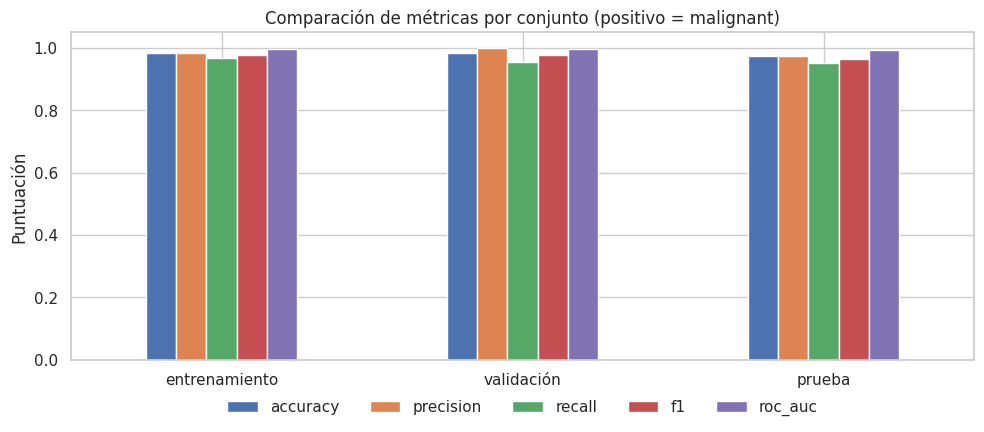

In [11]:
# 6.1 Métricas del modelo seleccionado en los tres conjuntos
metricas = pd.DataFrame({
    "entrenamiento": evaluar(modelo_final, X_train, y_train),
    "validación":    evaluar(modelo_final, X_val,   y_val),
    "prueba":        evaluar(modelo_final, X_test,  y_test),
}).T
display(metricas.round(4))

brechas = pd.DataFrame({
    "train - val":  metricas.loc["entrenamiento"] - metricas.loc["validación"],
    "val - prueba": metricas.loc["validación"] - metricas.loc["prueba"],
})
print("Diferencias entre conjuntos (positivo = el primero rinde más):")
display(brechas.round(4).T)

# Comparación visual de las métricas por conjunto
metricas.plot(kind="bar", figsize=(10, 4.5), ylim=(0, 1.05), rot=0,
              title="Comparación de métricas por conjunto (positivo = malignant)")
plt.ylabel("Puntuación")
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.08), ncol=5, frameon=False)
plt.tight_layout()
plt.show()

**Comparación entre conjuntos (clase positiva = *malignant*)**

| | Accuracy | Precision | Recall | F1 | ROC-AUC |
|---|---|---|---|---|---|
| Entrenamiento | 0.9824 | 0.9840 | 0.9685 | 0.9762 | 0.9979 |
| Validación | 0.9825 | 1.0000 | 0.9535 | 0.9762 | 0.9974 |
| Prueba | 0.9737 | 0.9756 | 0.9524 | 0.9639 | 0.9944 |

- **Sobreajuste:** no hay señales. Entrenamiento y validación rinden casi igual, y la caída en prueba es de ≈ 1 punto de F1, normal con solo 114 registros (un registro equivale a 0.9 puntos de *accuracy*).
- **Subajuste:** tampoco. Las métricas son altas en los tres conjuntos (*accuracy* > 0.97, ROC-AUC > 0.99).


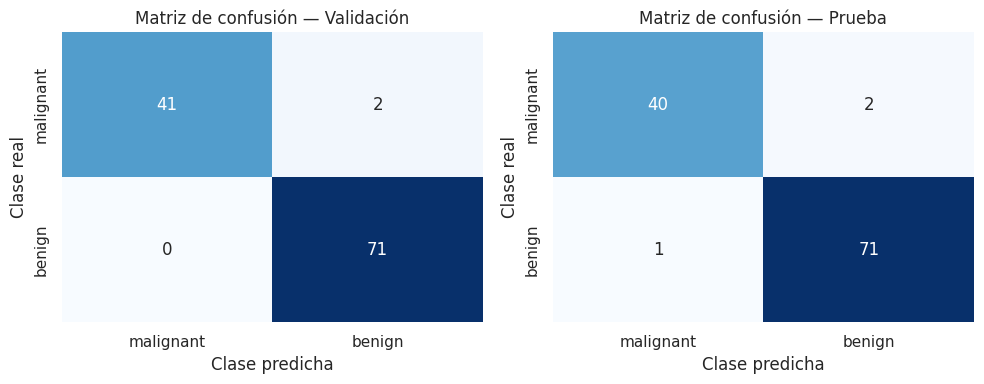

Conjunto de PRUEBA (clase positiva = malignant):
  Verdaderos positivos (maligno detectado):          40
  Falsos negativos (maligno clasificado benigno):    2
  Falsos positivos (benigno clasificado maligno):    1
  Verdaderos negativos (benigno detectado):          71


In [12]:
# 6.2 Matrices de confusión (validación y prueba)
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
etiquetas = ["malignant", "benign"]
for ax, (titulo, Xs, ys) in zip(axes, [("Validación", X_val, y_val), ("Prueba", X_test, y_test)]):
    cm = confusion_matrix(ys, modelo_final.predict(Xs), labels=[0, 1])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=etiquetas, yticklabels=etiquetas)
    ax.set_title(f"Matriz de confusión — {titulo}")
    ax.set_xlabel("Clase predicha")
    ax.set_ylabel("Clase real")
plt.tight_layout()
plt.show()

cm_test = confusion_matrix(y_test, modelo_final.predict(X_test), labels=[0, 1])
vp, fn, fp, vn = cm_test[0, 0], cm_test[0, 1], cm_test[1, 0], cm_test[1, 1]
print("Conjunto de PRUEBA (clase positiva = malignant):")
print(f"  Verdaderos positivos (maligno detectado):          {vp}")
print(f"  Falsos negativos (maligno clasificado benigno):    {fn}")
print(f"  Falsos positivos (benigno clasificado maligno):    {fp}")
print(f"  Verdaderos negativos (benigno detectado):          {vn}")

**Qué significan los errores aquí** (en prueba: 40 verdaderos positivos, 2 falsos negativos, 1 falso positivo y 71 verdaderos negativos)

- **Falso negativo:** un tumor maligno que el modelo clasifica como benigno. Es el error más riesgoso, porque retrasaría la detección. Ocurre 2 veces en 42 casos malignos.
- **Falso positivo:** un tumor benigno clasificado como maligno. Genera ansiedad y pruebas adicionales, pero se corrige con el seguimiento. Ocurre 1 vez en 72 casos benignos.

> En `scikit-learn` la clase 1 es *benign*; aquí se usó `pos_label=0` para que *precision* y *recall* midan la detección de la clase maligna.


              precision    recall  f1-score   support

   malignant     0.9756    0.9524    0.9639        42
      benign     0.9726    0.9861    0.9793        72

    accuracy                         0.9737       114
   macro avg     0.9741    0.9692    0.9716       114
weighted avg     0.9737    0.9737    0.9736       114



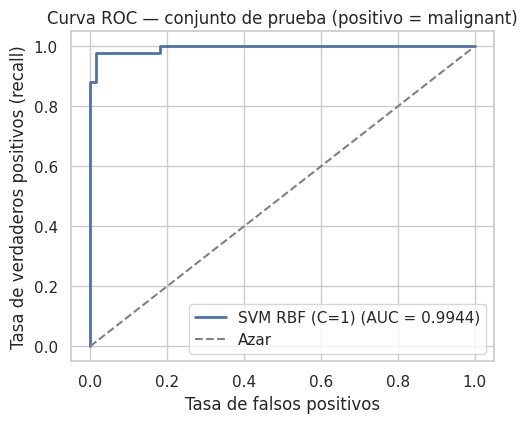

In [13]:
# 6.3 Reporte de clasificación y curva ROC en PRUEBA
print(classification_report(y_test, modelo_final.predict(X_test),
                            target_names=dataset.target_names, digits=4))

prob_mal = modelo_final.predict_proba(X_test)[:, list(modelo_final.classes_).index(MALIGNO)]
fpr, tpr, _ = roc_curve((y_test == MALIGNO).astype(int), prob_mal)
auc = roc_auc_score((y_test == MALIGNO).astype(int), prob_mal)

plt.figure(figsize=(5.2, 4.4))
plt.plot(fpr, tpr, lw=2, label=f"{nombre_final} (AUC = {auc:.4f})")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Azar")
plt.xlabel("Tasa de falsos positivos")
plt.ylabel("Tasa de verdaderos positivos (recall)")
plt.title("Curva ROC — conjunto de prueba (positivo = malignant)")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()

El reporte muestra *recall* de *malignant* de 0.9524 (40 de 42) y *precision* de 0.9756 (40 de 41 alertas correctas). El ROC-AUC de 0.9944 indica que el modelo casi siempre asigna mayor probabilidad a un caso maligno que a uno benigno. Con solo 42 casos malignos en prueba, cada error mueve el *recall* unos 2.4 puntos, por lo que estas cifras son estimaciones, no garantías.


### Etapa 7 — Serialización del modelo

Guarde el modelo y los pasos de preprocesamiento necesarios. Añada metadatos que permitan identificar el artefacto.


In [14]:
import joblib
import sklearn
from datetime import datetime

RUTA_MODELO = "modelo_cancer_mama_v1.joblib"

metadatos = {
    "model_id": "breast_cancer_clf_v1.0.0",
    "algoritmo": type(modelo_final.named_steps["clf"]).__name__,
    "configuracion": nombre_final,
    "preprocesamiento": [paso for paso, _ in modelo_final.steps if paso != "clf"],
    "variables_esperadas": list(X.columns),
    "clases": {"0": "malignant", "1": "benign"},
    "clase_positiva_para_metricas": "malignant (0)",
    "criterio_seleccion": "recall de malignant en validación",
    "fecha_creacion": datetime.now().isoformat(timespec="seconds"),
    "semilla": SEED,
    "metricas_prueba": {k: round(float(v), 4) for k, v in metricas.loc["prueba"].items()},
    "scikit_learn_version": sklearn.__version__,
}

# El Pipeline completo (escalador + clasificador) se guarda junto con sus metadatos
joblib.dump({"modelo": modelo_final, "metadatos": metadatos}, RUTA_MODELO)

print("Artefacto guardado:", RUTA_MODELO)
print("Pasos del Pipeline:", [p for p, _ in modelo_final.steps])
display(pd.Series(metadatos).to_frame("valor"))

Artefacto guardado: modelo_cancer_mama_v1.joblib
Pasos del Pipeline: ['scaler', 'clf']


,valor
model_id,breast_cancer_clf_v1.0.0
algoritmo,SVC
configuracion,SVM RBF (C=1)
preprocesamiento,[scaler]
variables_esperadas,"[mean radius, mean texture, mean perimeter, me..."
clases,"{'0': 'malignant', '1': 'benign'}"
clase_positiva_para_metricas,malignant (0)
criterio_seleccion,recall de malignant en validación
fecha_creacion,2026-11-17T01:31:48
semilla,42


Se guardó el **Pipeline completo** (`StandardScaler` + `SVC`) junto con sus metadatos (algoritmo, identificador de versión, variables esperadas, clases, fecha de creación, métricas de prueba y versión de `scikit-learn`) en `modelo_cancer_mama_v1.joblib`.

**Por qué guardar el preprocesamiento junto con el modelo**

1. El SVM se entrenó con datos **escalados**. Si solo se guardara el clasificador, los datos nuevos llegarían sin escalar (por ejemplo `mean area` ≈ 600) y las predicciones serían inválidas sin ningún aviso.
2. Si se recalculara un escalador con los datos nuevos, la transformación sería distinta a la del entrenamiento.
3. Un solo objeto garantiza que se aplica exactamente la misma transformación.


### Etapa 8 — Carga e inferencia

Cargue el artefacto guardado y utilícelo para predecir la clase de un registro nuevo.


In [15]:
# Sección independiente: no usa ninguna variable creada en las etapas anteriores.
import json
import joblib
import pandas as pd

RUTA_MODELO = "modelo_cancer_mama_v1.joblib"

# Solo se deben cargar archivos de fuentes confiables
artefacto = joblib.load(RUTA_MODELO)
modelo = artefacto["modelo"]
meta = artefacto["metadatos"]

print("Modelo:   ", meta["model_id"], f"({meta['algoritmo']})")
print("Creado:   ", meta["fecha_creacion"])
print("Pasos:    ", [p for p, _ in modelo.steps])
print("Variables esperadas:", len(meta["variables_esperadas"]))
print("Clases:   ", meta["clases"])

Modelo:    breast_cancer_clf_v1.0.0 (SVC)
Creado:    2026-11-17T01:31:48
Pasos:     ['scaler', 'clf']
Variables esperadas: 30
Clases:    {'0': 'malignant', '1': 'benign'}


Esta sección **no usa ninguna variable de las etapas anteriores**: importa las librerías y carga el artefacto desde el archivo. Solo se deben cargar archivos `joblib` de fuentes confiables.


In [16]:
VARIABLES = meta["variables_esperadas"]

def validar_registros(datos: pd.DataFrame) -> pd.DataFrame:
    """Verifica columnas, tipos y valores; devuelve el DataFrame en el orden esperado."""
    faltan = [c for c in VARIABLES if c not in datos.columns]
    sobran = [c for c in datos.columns if c not in VARIABLES]
    if faltan:
        raise ValueError(f"Faltan {len(faltan)} columnas: {faltan[:3]}...")
    if sobran:
        raise ValueError(f"Columnas no esperadas: {sobran}")
    datos = datos[VARIABLES]                      # mismo orden que en el entrenamiento
    no_numericas = [c for c in VARIABLES if not pd.api.types.is_numeric_dtype(datos[c])]
    if no_numericas:
        raise TypeError(f"Columnas no numéricas: {no_numericas}")
    if datos.isna().any().any():
        raise ValueError("Hay valores faltantes en el registro")
    if (datos < 0).any().any():
        raise ValueError("Las medidas del dataset son no negativas; hay valores negativos")
    return datos.astype(float)

# Registros nuevos (construidos a mano, con las 30 variables). Son valores sintéticos
# tomados de los perfiles promedio de cada clase y de un punto intermedio.
registros = pd.DataFrame([
    # registro_1: perfil parecido al promedio de tumores benignos
    dict(zip(VARIABLES, [
        12.1465, 17.9148, 78.0754, 462.7902, 0.0925, 0.0801,
        0.0461, 0.0257, 0.1742, 0.0629, 0.2841, 1.2204,
        2.0003, 21.1351, 0.0072, 0.0214, 0.026, 0.0099,
        0.0206, 0.0036, 13.3798, 23.5151, 87.0059, 558.8994,
        0.125, 0.1827, 0.1662, 0.0744, 0.2702, 0.0794,
    ])),
    # registro_2: perfil parecido al promedio de tumores malignos
    dict(zip(VARIABLES, [
        17.4628, 21.6049, 115.3654, 978.3764, 0.1029, 0.1452,
        0.1608, 0.088, 0.1929, 0.0627, 0.6091, 1.2109,
        4.3239, 72.6724, 0.0068, 0.0323, 0.0418, 0.0151,
        0.0205, 0.0041, 21.1348, 29.3182, 141.3703, 1422.2863,
        0.1448, 0.3748, 0.4506, 0.1822, 0.3235, 0.0915,
    ])),
    # registro_3: perfil intermedio (caso ambiguo)
    dict(zip(VARIABLES, [
        14.8047, 19.7599, 96.7204, 720.5833, 0.0977, 0.1127,
        0.1035, 0.0568, 0.1835, 0.0628, 0.4466, 1.2157,
        3.1621, 46.9038, 0.007, 0.0268, 0.0339, 0.0125,
        0.0205, 0.0039, 17.2573, 26.4167, 114.1881, 990.5928,
        0.1349, 0.2787, 0.3084, 0.1283, 0.2969, 0.0854,
    ])),
], index=["registro_1 (tipo benigno)", "registro_2 (tipo maligno)", "registro_3 (intermedio)"])

X_nuevo = validar_registros(registros)
print("Validación de columnas, tipos y valores: OK ->", X_nuevo.shape)

# Inferencia
clase_predicha = modelo.predict(X_nuevo)
probabilidades = modelo.predict_proba(X_nuevo)
nombres_clase = {int(k): v for k, v in meta["clases"].items()}

resultado = pd.DataFrame(probabilidades, index=X_nuevo.index,
                         columns=[f"prob_{nombres_clase[int(c)]}" for c in modelo.classes_])
resultado.insert(0, "clase_predicha", [nombres_clase[int(c)] for c in clase_predicha])
display(resultado.round(4))

# Resultado armado como mensaje (diccionario), listo para entregarse a otro sistema.
col_maligno = list(modelo.classes_).index(0)
mensajes = [
    {
        "record_id": idx,
        "model_id": meta["model_id"],
        "prediction": int(clase),
        "prediction_label": nombres_clase[int(clase)],
        "probability_malignant": round(float(prob[col_maligno]), 4),
    }
    for idx, clase, prob in zip(X_nuevo.index, clase_predicha, probabilidades)
]
print(json.dumps(mensajes[1], indent=2, ensure_ascii=False))

Validación de columnas, tipos y valores: OK -> (3, 30)


,clase_predicha,prob_malignant,prob_benign
registro_1 (tipo benigno),benign,0.0000,1.0000
registro_2 (tipo maligno),malignant,0.9999,0.0001
registro_3 (intermedio),malignant,0.8649,0.1351


{
  "record_id": "registro_2 (tipo maligno)",
  "model_id": "breast_cancer_clf_v1.0.0",
  "prediction": 0,
  "prediction_label": "malignant",
  "probability_malignant": 0.9999
}


**Resultado de la inferencia**

Los tres registros nuevos se construyeron a mano con las 30 variables, a partir de los promedios de cada clase y de un punto intermedio. **Son datos sintéticos de demostración, no pacientes reales.**

- `registro_1` (perfil benigno) → *benign*, probabilidad ≈ 1.0.
- `registro_2` (perfil maligno) → *malignant*, probabilidad 0.9999.
- `registro_3` (punto medio entre ambos) → *malignant* con 0.8649 frente a 0.1351 de *benign*: caso ambiguo, el modelo está menos seguro. Por eso conviene mostrar la probabilidad y no solo la clase.

Antes de predecir, `validar_registros` comprueba que estén exactamente las 30 columnas esperadas, que sean numéricas y que no haya faltantes ni negativos. El resultado también se arma como un mensaje (diccionario) con el identificador del modelo, la clase y la probabilidad, listo para entregarse a otro sistema.


In [17]:
# Prueba del control de entradas: un registro incompleto debe ser rechazado
registro_malo = registros.iloc[[0]].drop(columns=["mean area"])
try:
    validar_registros(registro_malo)
except ValueError as e:
    print("Rechazado correctamente ->", e)

Rechazado correctamente -> Faltan 1 columnas: ['mean area']...


El control funciona: un registro sin la columna `mean area` es rechazado con un mensaje claro en lugar de producir una predicción con datos incompletos.


### Etapa 9 — Conclusiones

Responda brevemente:

- ¿Qué modelo o configuración seleccionó y por qué?
- ¿Qué diferencia observa entre las métricas de entrenamiento, validación y prueba?
- ¿Qué métrica considera más relevante para este problema? Justifique.
- ¿Qué riesgo tendría optimizar únicamente accuracy?
- ¿Qué información y controles conservaría para reutilizar el modelo de forma reproducible?


In [18]:
# Resumen de lo que se necesita para reproducir y auditar el modelo
print("Modelo final:      ", nombre_final)
print("Semilla:           ", SEED)
print("Tamaños (tr/va/te):", len(X_train), len(X_val), len(X_test))
print("Versión sklearn:   ", sklearn.__version__)
print("Artefacto:         ", RUTA_MODELO)
display(metricas.round(4))

Modelo final:       SVM RBF (C=1)
Semilla:            42
Tamaños (tr/va/te): 341 114 114
Versión sklearn:    1.6.1
Artefacto:          modelo_cancer_mama_v1.joblib


,accuracy,precision,recall,f1,roc_auc
entrenamiento,0.9824,0.9840,0.9685,0.9762,0.9979
validación,0.9825,1.0000,0.9535,0.9762,0.9974
prueba,0.9737,0.9756,0.9524,0.9639,0.9944


**Resumen:** el modelo final es un SVM con kernel RBF (`C = 1`) precedido de `StandardScaler`. En prueba obtuvo *accuracy* 0.9737, *precision* 0.9756, *recall* 0.9524, F1 0.9639 y ROC-AUC 0.9944, con 2 falsos negativos y 1 falso positivo en 114 registros.

**1. ¿Qué modelo seleccionó y por qué?**
SVM RBF con `C = 1`. Empató con `C = 10` y con Gradient Boosting en el mejor *recall* de validación (0.9535), superó a Gradient Boosting en F1 y, frente a `C = 10`, tuvo menor brecha entre entrenamiento y validación (0.0000 frente a 0.0238), es decir, menos sobreajuste.

**2. ¿Qué diferencia observa entre entrenamiento, validación y prueba?**
Son muy parecidas (*accuracy* 0.982 / 0.983 / 0.974; *recall* 0.969 / 0.954 / 0.952). No hay señales claras de sobreajuste ni de subajuste. La pequeña caída en prueba está dentro de lo normal con 114 registros.

**3. ¿Qué métrica considera más relevante y por qué?**
El *recall* de la clase maligna, porque el error más costoso es no detectar un tumor maligno (falso negativo). Se complementa con *precision* y F1 para controlar las falsas alarmas.

**4. ¿Qué riesgo tendría optimizar únicamente *accuracy*?**
Con 62.7 % de casos benignos, un modelo que siempre dijera «benigno» tendría 62.7 % de *accuracy* sin detectar ningún maligno. Además, *accuracy* trata igual los dos tipos de error, aunque sus consecuencias son muy distintas.

**5. ¿Qué información y controles conservaría para reutilizar el modelo de forma reproducible?**
La semilla y la forma de dividir los datos; el Pipeline completo (escalador + modelo) con sus hiperparámetros; la lista y el orden de las 30 variables; el identificador de versión del modelo; las versiones de Python y `scikit-learn`; las métricas de referencia y la fecha; y la validación de las entradas en cada inferencia.

**Limitaciones del ejercicio**

- Conjunto pequeño (569 registros) y de una sola fuente; solo 42 casos malignos en prueba, así que las métricas tienen un margen de error amplio.
- Una sola división entrenamiento/validación/prueba: otra semilla podría dar cifras algo distintas.
- Las variables son medidas ya calculadas, no imágenes ni historia clínica, y no hay validación con datos de otras instituciones.
- Se usó el umbral por defecto (0.5) y no se revisó la calibración de las probabilidades.

**Controles adicionales antes de usarlo en producción**

- Validar el modelo con datos nuevos y representativos del entorno real.
- Ajustar el umbral según el costo de los errores (priorizar el *recall*).
- Monitorear la calidad de los datos de entrada y el desempeño del modelo en el tiempo, con un plan de reentrenamiento.
- Usarlo solo como apoyo a la decisión, con revisión humana de los casos de baja certeza.
- Revisión ética y regulatoria, protección de datos personales y carga de artefactos solo de fuentes confiables.

> Este ejercicio es educativo y **no debe usarse como herramienta de diagnóstico médico**.
